# Notebook B: chia dữ liệu, mô hình và câu hỏi thứ ba

**Đề tài:** Một quy tắc một dòng so với mười mô hình trên bộ dữ liệu lừa đảo trực tuyến phổ biến và độ chính xác gần tuyệt đối thật ra đo điều gì

**Sinh viên B** chạy sau khi Notebook A đã tạo file parquet, `sql/queries.sql` và `manifest.json`. Notebook này không cần kernel của Notebook A.

## Kiểm tra bàn giao

- **Làm gì:** đọc manifest và so mã băm của file parquet.
- **Vì sao:** bảo đảm hai notebook dùng đúng cùng một dữ liệu.
- **Kiểm tra:** ô in `handover ok`.

In [1]:
# run once per machine, then comment out
# %pip install pandas numpy duckdb pyarrow scikit-learn lightgbm xgboost matplotlib scipy
import os, json, hashlib, numpy as np, pandas as pd, warnings
warnings.filterwarnings('ignore')
m = json.load(open('data/processed/manifest.json'))
assert hashlib.md5(open(m['file'], 'rb').read()).hexdigest() == m['md5'], 'parquet differs from the manifest, rerun Notebook A'
os.makedirs('report', exist_ok=True); print('handover ok', m['rows'], 'rows')

handover ok 235370 rows


## Bước 4. Bảng đặc trưng và chia dữ liệu

- **Làm gì:** chạy lại `sql/queries.sql`, lấy bảng `feat`, chia tập huấn luyện và kiểm thử theo giao thức của đề tài.
- **Vì sao:** cách chia quyết định con số có đáng tin hay không; dòng `assert` là phép kiểm tra rò rỉ.
- **Kiểm tra:** ghi số dòng hai tập và số đặc trưng vào bảng mô tả thực nghiệm.

In [2]:
# Step 4: stratified split into training, validation (for the alarm threshold) and test; feature groups by availability
import duckdb
from sklearn.model_selection import train_test_split
con = duckdb.connect(); con.execute(open('sql/queries.sql').read())
feat = con.execute("SELECT * FROM feat ORDER BY row_id").df()
SHORTCUT = ['URLSimilarityIndex']
ADDRESS = [c for c in ['URLLength', 'DomainLength', 'IsDomainIP', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation',
           'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL',
           'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS'] if c in feat.columns]
PAGE = [c for c in feat.columns if c not in SHORTCUT + ADDRESS + ['Domain', 'TLD', 'label', 'phishing', 'row_id', 'domain_seen_times', 'starts_https_www']]
X_cols = SHORTCUT + ADDRESS + PAGE; TARGET = 'phishing'
pool = feat.sample(min(len(feat), 100_000), random_state=0)                  # a fixed sample keeps ten models and five seeds within minutes
train, rest = train_test_split(pool, test_size=0.4, random_state=0, stratify=pool[TARGET]); valid, test = train_test_split(rest, test_size=0.5, random_state=0, stratify=rest[TARGET])
X_tr, y_tr, X_te, y_te = train[X_cols], train[TARGET], test[X_cols], test[TARGET]
assert set(train.row_id).isdisjoint(test.row_id) and set(train.row_id).isdisjoint(valid.row_id)      # leakage check
print(len(train), len(valid), len(test), len(X_cols), 'features:', len(SHORTCUT), 'shortcut,', len(ADDRESS), 'address,', len(PAGE), 'page')

60000 20000 20000 50 features: 1 shortcut, 21 address, 28 page


## Bước 4b. Hiểu tập huấn luyện và tập kiểm thử

Ba ô dưới đây kiểm tra hai tập có giống nhau không và đặc trưng nào mạnh nhất, trước khi huấn luyện bất kỳ mô hình nào.

### 4b.1 Mục tiêu ở hai tập

- **Làm gì:** so phân phối của mục tiêu giữa tập huấn luyện và tập kiểm thử.
- **Vì sao:** hai phân phối lệch nhau giải thích vì sao mô hình cây ngoại suy kém.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [3]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#C95B91' if i == highlight else '#F0C6D8' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

import matplotlib.pyplot as plt
def nice(v, label):                                     # readable numbers on the bars
    v = np.asarray(v, dtype=float); m = np.nanmax(np.abs(v))
    return (v / 1e6, label + ' (million)', '{:.2f}') if m >= 1e6 else (v / 1e3, label + ' (thousand)', '{:.1f}') if m >= 1e4 else (v, label, '{:.2f}' if m < 100 else '{:.0f}')
ytr, yte = pd.Series(np.asarray(y_tr, dtype=float)), pd.Series(np.asarray(y_te, dtype=float)); BINARY = ytr.nunique() <= 2
print('train rows', len(ytr), 'test rows', len(yte), 'features', X_tr.shape[1])
if BINARY: print('positive share: train %.3f, test %.3f' % (ytr.mean(), yte.mean()))
else:
    fig, ax = plt.subplots(figsize=(6.5, 3)); lo, hi = min(ytr.quantile(.01), yte.quantile(.01)), max(ytr.quantile(.99), yte.quantile(.99)); bins = np.linspace(lo, hi, 50)
    ax.hist(ytr.clip(lo, hi), bins=bins, density=True, alpha=.6, color='#C95B91', label='Train'); ax.hist(yte.clip(lo, hi), bins=bins, density=True, alpha=.6, color='#A9C4E2', label='Test')
    ax.legend(frameon=False); ax.set_xlabel('Target'); ax.set_ylabel('Density'); ax.spines[['top', 'right']].set_visible(False); fig.tight_layout(); fig.savefig('report/fig_split_target.png', dpi=200); plt.show()
    print(pd.DataFrame({'train': ytr.describe(), 'test': yte.describe()}).round(3))

train rows 60000 test rows 20000 features 50
positive share: train 0.429, test 0.429


### 4b.2 Đặc trưng lệch giữa hai tập

- **Làm gì:** độ lệch trung bình chuẩn hoá của từng đặc trưng giữa hai tập.
- **Kiểm tra:** đặc trưng lệch trên 0,5 độ lệch chuẩn là nguồn rủi ro, nêu trong mục Limitations.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [4]:
A_, B_ = X_tr.astype(float), X_te.astype(float); sd = A_.std().replace(0, np.nan)
shift = ((B_.mean() - A_.mean()) / sd).abs().sort_values(ascending=False).rename('abs_standardised_mean_difference')
shift.to_csv('report/table_split_shift.csv'); display(shift.head(10).round(3).to_frame())
print('features whose test mean lies more than 0.5 training standard deviations away:', int((shift > 0.5).sum()), 'of', len(shift))

,abs_standardised_mean_difference
NoOfJS,0.024
NoOfSelfRedirect,0.014
LetterRatioInURL,0.011
IsResponsive,0.011
SpacialCharRatioInURL,0.011
NoOfEmptyRef,0.011
NoOfPopup,0.011
HasHiddenFields,0.010
CharContinuationRate,0.010
URLTitleMatchScore,0.009


features whose test mean lies more than 0.5 training standard deviations away: 0 of 50


### 4b.3 Sức mạnh của từng đặc trưng

- **Làm gì:** tương quan hạng giữa từng đặc trưng và mục tiêu trên tập huấn luyện.
- **Vì sao:** nếu một đặc trưng đã gần đủ, mô hình phức tạp sẽ không hơn nhiều, và đó là thông tin để chọn câu hỏi.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [5]:
sig = A_.sample(min(len(A_), 20_000), random_state=0); ys = pd.Series(np.asarray(y_tr, dtype=float), index=X_tr.index).loc[sig.index]
strength = sig.corrwith(ys, method='spearman').abs().sort_values(ascending=False).rename('abs_rank_correlation_with_target')
strength.to_csv('report/table_feature_strength.csv'); display(strength.head(10).round(3).to_frame())
print('strongest single feature:', strength.index[0], round(float(strength.iloc[0]), 3), '-> a model must beat what this feature already gives')

,abs_rank_correlation_with_target
URLSimilarityIndex,0.945
NoOfImage,0.841
NoOfExternalRef,0.841
LineOfCode,0.840
NoOfSelfRef,0.827
NoOfJS,0.820
NoOfCSS,0.801
HasSocialNet,0.783
HasCopyrightInfo,0.745
HasDescription,0.696


strongest single feature: URLSimilarityIndex 0.945 -> a model must beat what this feature already gives


## Bước 6a. So sánh mô hình (RQ2)

- **Làm gì:** huấn luyện mười mô hình với năm seed trên cùng cách chia.
- **Vì sao:** so nhiều họ mô hình để kết luận không phụ thuộc một kiểu mô hình; năm seed cho độ lệch chuẩn.
- **Kiểm tra:** chênh lệch nhỏ hơn độ lệch chuẩn thì chưa được kết luận mô hình nào hơn. Bảng lưu ở `report/table_rq2.csv`.

In [6]:
# Step 6a: ten classifiers from four families, five seeds, same stratified split, phishing against legitimate addresses; probability metrics because one class is rare
import numpy as np, pandas as pd, time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
sc = lambda m: make_pipeline(StandardScaler(), m)       # scaling for linear, distance and neural models
models = {
    'Logistic':       lambda s: sc(LogisticRegression(max_iter=500, random_state=s)),
    'Linear SVM':     lambda s: sc(LinearSVC(C=1.0, random_state=s)),
    'k-NN':           lambda s: sc(KNeighborsClassifier(n_neighbors=15)),
    'Decision Tree':  lambda s: DecisionTreeClassifier(max_depth=12, min_samples_leaf=5, random_state=s),
    'Random Forest':  lambda s: RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s),
    'Extra Trees':    lambda s: ExtraTreesClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s),
    'HistGB':         lambda s: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=s),
    'LightGBM':       lambda s: LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
                                               subsample_freq=1, colsample_bytree=0.8, random_state=s, verbose=-1),
    'XGBoost':        lambda s: XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8,
                                              colsample_bytree=0.8, tree_method='hist', random_state=s),
    'Small MLP':      lambda s: sc(MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=200, early_stopping=True,
                                                 random_state=s)),
}
def proba(m, X):                                        # probability of the positive class for every model family
    if hasattr(m, 'predict_proba'): return m.predict_proba(X)[:, 1]
    return 1 / (1 + np.exp(-m.decision_function(X)))
rows, fitted = [], {}
for name, make in models.items():
    aucs, aps, briers, secs = [], [], [], []
    for seed in range(5):
        m = make(seed); t0 = time.perf_counter(); m.fit(X_tr, y_tr); secs.append(time.perf_counter() - t0)
        p = proba(m, X_te); aucs.append(roc_auc_score(y_te, p)); aps.append(average_precision_score(y_te, p))
        briers.append(brier_score_loss(y_te, p))
    fitted[name] = m                                    # keep the last fitted model of each family for Step 6b
    rows.append([name, np.mean(aucs), np.std(aucs), np.mean(aps), np.mean(briers), np.mean(secs)])
res = pd.DataFrame(rows, columns=['model', 'ROC_AUC', 'sd', 'PR_AUC', 'Brier', 'train_s'])
res.to_csv('report/table_rq2.csv', index=False); print(res.round(4))

           model  ROC_AUC   sd  PR_AUC   Brier  train_s
0       Logistic   1.0000  0.0  1.0000  0.0001   0.3782
1     Linear SVM   1.0000  0.0  1.0000  0.0018   0.5693
2           k-NN   0.9996  0.0  0.9996  0.0018   0.1427
3  Decision Tree   1.0000  0.0  1.0000  0.0000   0.2009
4  Random Forest   1.0000  0.0  1.0000  0.0002   8.7212
5    Extra Trees   1.0000  0.0  1.0000  0.0006  10.1815
6         HistGB   1.0000  0.0  1.0000  0.0001   2.7587
7       LightGBM   1.0000  0.0  1.0000  0.0000   1.8337
8        XGBoost   1.0000  0.0  1.0000  0.0000   2.6935
9      Small MLP   1.0000  0.0  1.0000  0.0003   3.9681


### Hình RQ2

- **Làm gì:** vẽ kết quả các mô hình, tô màu nhấn mô hình tốt nhất.
- **Kiểm tra:** số trên cột khớp với `report/table_rq2.csv`.

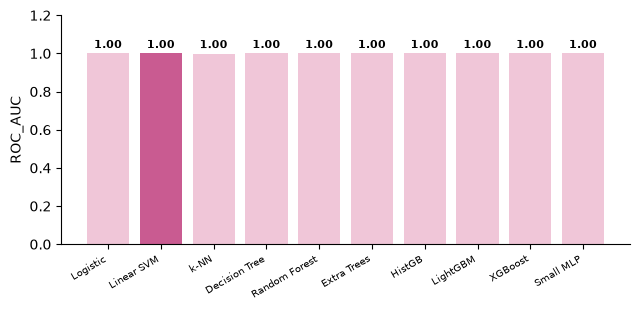

In [7]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#C95B91' if i == highlight else '#F0C6D8' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

bar_chart(res.model, res.iloc[:, 1], res.columns[1], 'report/fig_rq2_models.png', highlight=int(res.iloc[:, 1].idxmax()), fmt='{:.2f}')

## Cổng khả thi: có nên xoay câu hỏi không

- **Làm gì:** so mô hình tốt nhất với mốc đơn giản và in ra một trong ba kết luận.
- **Vì sao:** nếu mô hình không hơn mốc hoặc bài toán quá dễ, nhóm xoay câu hỏi ngay ở đây thay vì cố chỉnh mô hình. Xoay câu hỏi nghĩa là đổi điều được hỏi cho khớp với điều dữ liệu trả lời được, không phải chọn lại số liệu cho đẹp.

**Các hướng xoay của đề tài này:**

1. Mọi mô hình đạt gần 100% là kết quả chính, không phải lỗi: giữ trục "vì sao dễ" và quy tắc một dòng.
2. Nếu muốn thêm một kết quả dương: báo mô hình nhỏ nhất đạt cùng điểm số với chi phí thấp hơn hàng nghìn lần.
3. Nếu phản biện đòi bài toán khó hơn: chỉ giữ các địa chỉ lừa đảo bắt đầu bằng https://www. và đo lại tỷ lệ bắt được.

**Quyết định của nhóm (giữ câu hỏi hay xoay theo hướng nào, vì sao):** ...

In [8]:
best = res.sort_values('ROC_AUC').iloc[-1]; spread = res.ROC_AUC.max() - res.ROC_AUC.min()
print('best model %s: ROC-AUC %.4f, PR-AUC %.4f | spread between models %.4f' % (best.model, best.ROC_AUC, best.PR_AUC, spread))
verdict = 'TOO EASY: every model is near the ceiling, so the comparison says little; explain why the task is easy or use a harder protocol (RQ3)' if best.ROC_AUC >= 0.995 else 'GOOD: there is a clear signal and room to compare models' if best.ROC_AUC >= 0.75 else 'WEAK: the signal is weak, pivot the target or the features (see the options above) and report this result honestly'
print(verdict); pd.Series({'best_model': best.model, 'ROC_AUC': best.ROC_AUC, 'PR_AUC': best.PR_AUC, 'spread': spread, 'verdict': verdict}).to_csv('report/table_feasibility_gate.csv')

best model XGBoost: ROC-AUC 1.0000, PR-AUC 1.0000 | spread between models 0.0004
TOO EASY: every model is near the ceiling, so the comparison says little; explain why the task is easy or use a harder protocol (RQ3)


## Bước 6b. Câu hỏi thứ ba (RQ3)

- **Làm gì:** Huấn luyện lại mười mô hình này trên sáu bộ đặc trưng và cả mười mô hình khi chỉ huấn luyện trên ba tên miền cấp cao phổ biến nhất.
- **Vì sao:** đây là đóng góp chính của bài; mỗi bảng `report/table_rq3_*.csv` ứng với một ý trong mục Results.
- **Kiểm tra:** đọc từng bảng in ra và viết một câu kết luận có số cho mỗi bảng. Nếu kết quả trái dự kiến trong đề cương thì báo đúng như vậy và tìm nguyên nhân, không chỉnh code cho ra kết quả mong muốn.

In [9]:
# Step 6b: RQ3, how much of the near-perfect score rests on one feature, what an address-only detector achieves, and what happens on top-level domains never seen
FPR = 0.01                                               # false-alarm budget: at most 1% of legitimate addresses may be blocked
def caught(m, cols, A, V, B):                            # share of phishing caught when the threshold is set on validation data at the budget
    m.fit(A[cols], A[TARGET]); t = np.quantile(proba(m, V.loc[V[TARGET] == 0, cols]), 1 - FPR); p = proba(m, B[cols])
    return roc_auc_score(B[TARGET], p), float((p[B[TARGET].to_numpy() == 1] >= t).mean()), float((p[B[TARGET].to_numpy() == 0] >= t).mean())
SETS = {'1 all features': X_cols, '2 without the similarity index': ADDRESS + PAGE, '3 address only, with the similarity index': SHORTCUT + ADDRESS,
        '4 address only, no similarity index': ADDRESS, '5 address only, no similarity index, no TLD statistics': [c for c in ADDRESS if c not in ('TLDLegitimateProb', 'URLCharProb')],
        '6 page only': PAGE}
rows = []
for tag, cols in SETS.items():                           # (1) feature ladder for all ten models
    for name, make in models.items():
        auc, det, fa = caught(make(0), cols, train, valid, test); rows.append([tag, name, len(cols), auc, det, fa])
lad = pd.DataFrame(rows, columns=['feature_set', 'model', 'n_features', 'ROC_AUC', 'caught_at_1pct_false_alarms', 'false_alarm_rate'])
lad.to_csv('report/table_rq3_feature_ladder.csv', index=False)
print(lad.groupby('feature_set').agg(n_features=('n_features', 'first'), ROC_AUC=('ROC_AUC', 'mean'), caught_mean=('caught_at_1pct_false_alarms', 'mean'), caught_best=('caught_at_1pct_false_alarms', 'max')).round(4))
one = feat[SHORTCUT[0]]; yy = feat[TARGET].to_numpy(); flag = 1 - feat.starts_https_www.to_numpy()      # one-line rule: phishing unless the address starts with https://www.
rule = pd.Series({'ROC_AUC_of_similarity_index_alone': roc_auc_score(yy, -one), 'legitimate_with_index_100_pct': float(100 * (one[yy == 0] >= 100).mean()),
        'rule_accuracy': float((flag == yy).mean()), 'rule_caught': float(flag[yy == 1].mean()), 'rule_false_alarm_rate': float(flag[yy == 0].mean()),
        'best_model_accuracy_all_features': float(max((proba(m, X_te) >= 0.5).astype(int).__eq__(y_te.to_numpy()).mean() for m in fitted.values()))})
rule.rename('value').to_csv('report/table_rq3_one_line_rule.csv'); print(rule.round(4))
# (2) top-level domains never seen in training: the rarer domains are held out as a group
FAM = list(models); big = pool.TLD.value_counts().index[:3]; rows = []
A = train[train.TLD.isin(big)]; V = valid[valid.TLD.isin(big)]; B_in = test[test.TLD.isin(big)]; B_out = test[~test.TLD.isin(big)]
for tag, cols in [('all features', X_cols), ('address only, no similarity index', ADDRESS)]:
    for name in FAM:
        a1, d1, f1 = caught(models[name](0), cols, A, V, B_in); m = models[name](0).fit(A[cols], A[TARGET])
        t = np.quantile(proba(m, V.loc[V[TARGET] == 0, cols]), 1 - FPR); p = proba(m, B_out[cols]); yb = B_out[TARGET].to_numpy()
        rows.append([tag, name, len(B_in), len(B_out), d1, float((p[yb == 1] >= t).mean()), f1, float((p[yb == 0] >= t).mean())])
tld = pd.DataFrame(rows, columns=['features', 'model', 'test_seen_tld', 'test_unseen_tld', 'caught_seen_tld', 'caught_unseen_tld', 'false_alarms_seen_tld', 'false_alarms_unseen_tld'])
tld.to_csv('report/table_rq3_unseen_tld.csv', index=False); print('training top-level domains:', list(big)); print(tld.round(3))

                                                    n_features  ROC_AUC  \
feature_set                                                               
1 all features                                              50   1.0000   
2 without the similarity index                              49   0.9998   
3 address only, with the similarity index                   22   0.9999   
4 address only, no similarity index                         21   0.9983   
5 address only, no similarity index, no TLD sta...          19   0.9980   
6 page only                                                 28   0.9991   

                                                    caught_mean  caught_best  
feature_set                                                                   
1 all features                                           0.9999       1.0000  
2 without the similarity index                           0.9997       1.0000  
3 address only, with the similarity index                0.9998       1.0000  
4 ad

### Bước 6b-2. Đối chứng cùng kích thước cho phép thử tên miền chưa thấy

- **Làm gì:** huấn luyện lại cả mười mô hình trên một mẫu ngẫu nhiên lấy từ mọi tên miền cấp cao, có cùng số dòng huấn luyện và validation với mẫu chỉ gồm .com, .org, .net; đánh giá trên đúng tập kiểm thử tên miền chưa thấy. Chạy cho bộ 21 đặc trưng địa chỉ và bộ 19 đặc trưng (bỏ `TLDLegitimateProb`, `URLCharProb`).
- **Vì sao:** phép thử tên miền chưa thấy đổi cả mức đa dạng tên miền lẫn số dòng huấn luyện; đối chứng này tách hai yếu tố.
- **Kiểm tra:** `report/table_rq3_size_matched_control.csv` tồn tại; cột `FA_holdout_seed0` khớp cột báo động giả của tên miền chưa thấy ở `table_rq3_unseen_tld.csv`.

In [10]:
# Step 6b-2: size-matched random control for the unseen-TLD test (same training size, same validation size, same test set; TLDs are not restricted)
FAM = list(models)
ADDR19 = [c for c in ADDRESS if c not in ('TLDLegitimateProb', 'URLCharProb')]
def caught_fa(m, cols, Vd, Bd):                          # catch rate and false-alarm rate at the 1% validation threshold
    t = np.quantile(proba(m, Vd.loc[Vd[TARGET] == 0, cols]), 1 - FPR); p = proba(m, Bd[cols]); y = Bd[TARGET].to_numpy()
    return float((p[y == 1] >= t).mean()), float((p[y == 0] >= t).mean())
rows = []
for tag, cols in [('address only, no similarity index', ADDRESS), ('address only, no similarity index, no TLD statistics', ADDR19)]:
    for name in FAM:
        hold = np.array([caught_fa(models[name](s).fit(A[cols], A[TARGET]), cols, V, B_out) for s in range(5)])      # seed 0 is the row in the unseen-TLD table
        ctrl = []
        for d in range(5):                               # five random draws of the same size as A and V, taken from all TLDs
            Ar, Vr = train.sample(len(A), random_state=d), valid.sample(len(V), random_state=d)
            ctrl.append(caught_fa(models[name](d).fit(Ar[cols], Ar[TARGET]), cols, Vr, B_out))
        ctrl = np.array(ctrl)
        rows.append([tag, name, len(A), len(B_out), int((B_out[TARGET] == 0).sum()), hold[0, 0], hold[0, 1], hold[:, 1].mean(), hold[:, 1].std(), ctrl[:, 0].mean(), ctrl[:, 1].mean(), ctrl[:, 1].std()])
ctl = pd.DataFrame(rows, columns=['features', 'model', 'n_train', 'n_test_unseen', 'n_legit_unseen', 'caught_holdout_seed0', 'FA_holdout_seed0',
                                  'FA_holdout_mean5', 'FA_holdout_sd5', 'caught_control_mean5', 'FA_control_mean5', 'FA_control_sd5'])
ctl.to_csv('report/table_rq3_size_matched_control.csv', index=False); print(ctl.round(4).to_string())

                                                features          model  n_train  n_test_unseen  n_legit_unseen  caught_holdout_seed0  FA_holdout_seed0  FA_holdout_mean5  FA_holdout_sd5  caught_control_mean5  FA_control_mean5  FA_control_sd5
0                      address only, no similarity index       Logistic    35202           8286            3805                0.9958            0.0715            0.0715          0.0000                0.9959            0.0152          0.0008
1                      address only, no similarity index     Linear SVM    35202           8286            3805                0.9969            0.3246            0.3246          0.0000                0.9969            0.0143          0.0015
2                      address only, no similarity index           k-NN    35202           8286            3805                0.9949            0.1714            0.1714          0.0000                0.9942            0.0128          0.0010
3                      address o

### Bước 6b-3. Chẩn đoán ngưỡng cho phép thử tên miền chưa thấy

- **Làm gì:** với 21 đặc trưng địa chỉ và seed 0, đếm số giá trị điểm khác nhau của URL hợp pháp trong validation, tỷ lệ báo động giả thực tế tại ngưỡng phân vị 99 trên validation, và (riêng Linear SVM) các phân vị của điểm quyết định ở validation so với tên miền chưa thấy.
- **Vì sao:** k-NN và Decision Tree cho rất ít giá trị điểm khác nhau nên ngưỡng phân vị 99 có thể rơi vào một điểm trùng và cho báo động giả trên validation cao hơn 1%; Linear SVM có báo động giả cao nhất ở tên miền chưa thấy và cần một chẩn đoán.
- **Kiểm tra:** `report/table_rq3_threshold_diagnostic.csv` và `report/table_rq3_svm_score_quantiles.csv` tồn tại; cột `unseen_FA_at_threshold` khớp cột báo động giả của tên miền chưa thấy ở `table_rq3_unseen_tld.csv` cho bộ đặc trưng địa chỉ.

In [11]:
# Step 6b-3: threshold diagnostic for the unseen-TLD test (21 address features, seed 0)
rows = []
for name in models:
    m = models[name](0).fit(A[ADDRESS], A[TARGET]); pv = proba(m, V.loc[V[TARGET] == 0, ADDRESS]); po = proba(m, B_out.loc[B_out[TARGET] == 0, ADDRESS]); thr = float(np.quantile(pv, 1 - FPR))
    rows.append([name, len(np.unique(pv)), float((pv >= thr).mean()), float((po >= thr).mean())])
dg = pd.DataFrame(rows, columns=['model', 'distinct_valid_legit_scores', 'valid_FA_at_threshold', 'unseen_FA_at_threshold'])
dg.to_csv('report/table_rq3_threshold_diagnostic.csv', index=False); print(dg.round(4).to_string())
svm_m = models['Linear SVM'](0).fit(A[ADDRESS], A[TARGET])      # decision-function scores of legitimate addresses: validation (seen TLDs) against test (unseen TLDs)
dv = svm_m.decision_function(V.loc[V[TARGET] == 0, ADDRESS]); do = svm_m.decision_function(B_out.loc[B_out[TARGET] == 0, ADDRESS]); thr_svm = float(np.quantile(dv, 1 - FPR))
sq = pd.DataFrame({'quantile': [0.50, 0.90, 0.99], 'valid_legit_decision': np.quantile(dv, [0.50, 0.90, 0.99]), 'unseen_legit_decision': np.quantile(do, [0.50, 0.90, 0.99])})
sq.to_csv('report/table_rq3_svm_score_quantiles.csv', index=False); print(sq.round(3).to_string(index=False)); print('threshold on the decision scale: %.3f; unseen legitimate above it: %.4f' % (thr_svm, float((do >= thr_svm).mean())))


           model  distinct_valid_legit_scores  valid_FA_at_threshold  unseen_FA_at_threshold
0       Logistic                         7584                 0.0100                  0.0715
1     Linear SVM                         7584                 0.0100                  0.3246
2           k-NN                           11                 0.0466                  0.1714
3  Decision Tree                           23                 0.0204                  0.1921
4  Random Forest                         2487                 0.0100                  0.1611
5    Extra Trees                         4066                 0.0100                  0.0933
6         HistGB                         1760                 0.0100                  0.0741
7       LightGBM                         3533                 0.0100                  0.0544
8        XGBoost                         3275                 0.0100                  0.1658
9      Small MLP                         7584                 0.0100  

## Bước 6c. Kiểm tra bổ sung và bảng tham số

- **Làm gì:** chạy phép kiểm tra bổ sung của đề tài và lưu tham số mô hình.
- **Vì sao:** bảng này đi vào phần thảo luận và phụ lục của bài.
- **Kiểm tra:** `report/params_best.json` tồn tại.

In [12]:
# Step 6c: cost of each detector per address, the most useful address features, and parameters
import pickle
rows = []
for name in models:                                      # address-only detector: stored size and time per address on this machine
    m = models[name](0).fit(train[ADDRESS], y_tr); [proba(m, test[ADDRESS]) for _ in range(3)]      # three warm-up calls, not timed
    reps = []
    for _ in range(7):                               # median of 7 timed calls, so one noisy call does not move the result
        t0 = time.perf_counter(); proba(m, test[ADDRESS]); reps.append(1e6 * (time.perf_counter() - t0) / len(test))
    us = float(np.median(reps))
    r = lad[(lad.feature_set == '4 address only, no similarity index') & (lad.model == name)].iloc[0]
    rows.append([name, len(pickle.dumps(m)) / 1024, us, r.caught_at_1pct_false_alarms])
edge = pd.DataFrame(rows, columns=['model', 'size_kB', 'microseconds_per_address', 'caught_at_1pct_false_alarms']); edge.to_csv('report/table_rq3_cost.csv', index=False); print(edge.round(3))
from sklearn.inspection import permutation_importance
best = edge.sort_values('caught_at_1pct_false_alarms').model.iloc[-1]; m = models[best](0).fit(train[ADDRESS], y_tr); s = test.sample(min(5000, len(test)), random_state=0)
imp = permutation_importance(m, s[ADDRESS], s[TARGET], scoring='roc_auc', n_repeats=3, random_state=0)
top = pd.DataFrame({'feature': ADDRESS, 'drop_in_ROC_AUC': imp.importances_mean}).sort_values('drop_in_ROC_AUC', ascending=False).head(8); top.to_csv('report/table_rq3_address_features.csv', index=False); print(best); print(top.round(4))
import json
json.dump({'best_address_only_model': best, 'false_alarm_budget': FPR, 'params': {k: str(v) for k, v in models[best](0).get_params().items()}}, open('report/params_best.json', 'w'), indent=2)

           model    size_kB  microseconds_per_address  \
0       Logistic      2.178                     0.375   
1     Linear SVM      2.066                     0.275   
2           k-NN  10314.504                   187.208   
3  Decision Tree     22.084                     0.206   
4  Random Forest  18284.763                    11.939   
5    Extra Trees  19039.160                    11.898   
6         HistGB    498.635                     5.851   
7       LightGBM   1023.987                    13.077   
8        XGBoost    711.439                     3.059   
9      Small MLP     91.499                     1.398   

   caught_at_1pct_false_alarms  
0                        0.996  
1                        0.997  
2                        0.995  
3                        0.994  
4                        0.996  
5                        0.995  
6                        0.996  
7                        0.996  
8                        0.996  
9                        0.995  
Linear SV

### Hình RQ3

- **Làm gì:** vẽ hai hình RQ3 từ các bảng `report/table_rq3_*.csv` bằng hàm `bar_chart` ở trên, theo mẫu Hình 4 và Hình 5 của đề cương.
- **Kiểm tra:** mỗi hình một ý, chữ tiếng Anh, số in đậm trên cột.

report\table_rq3_address_features.csv (8, 2)


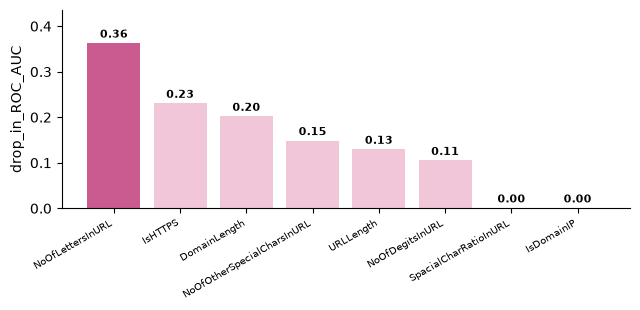

report\table_rq3_cost.csv (10, 4)


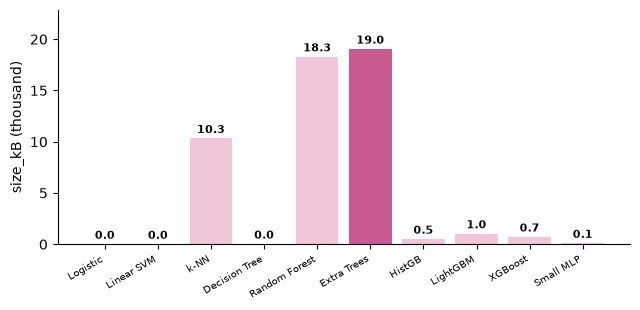

report\table_rq3_feature_ladder.csv (60, 6)
report\table_rq3_one_line_rule.csv (6, 2)


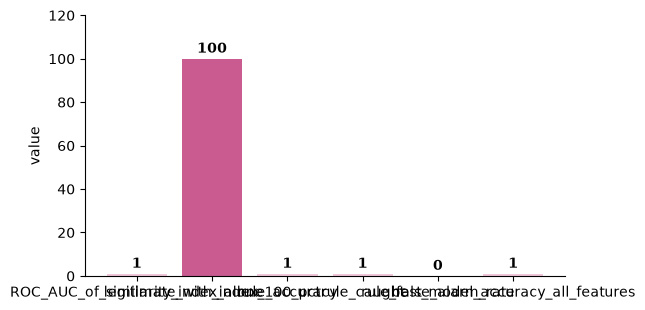

report\table_rq3_size_matched_control.csv (20, 12)


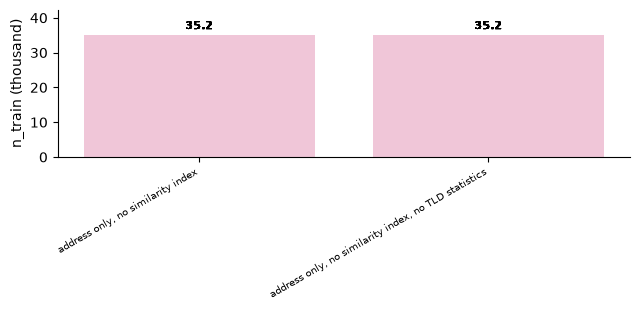

report\table_rq3_svm_score_quantiles.csv (3, 3)
report\table_rq3_threshold_diagnostic.csv (10, 4)


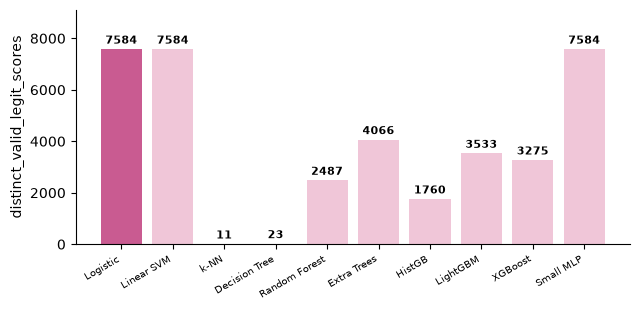

report\table_rq3_unseen_tld.csv (20, 8)


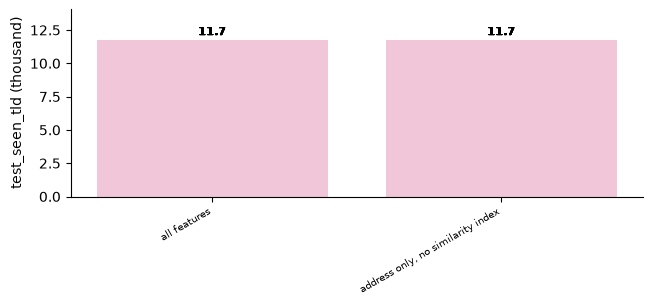

In [13]:
import glob
for f in sorted(glob.glob('report/table_rq3_*.csv')):
    t = pd.read_csv(f); numc = [c for c in t.columns[1:] if pd.api.types.is_numeric_dtype(t[c])]
    print(f, t.shape)
    if 2 <= len(t) <= 20 and numc and t[numc[0]].notna().all() and t[numc[0]].min() >= 0 and t[numc[0]].max() > 0:
        v, lab, fm = nice(t[numc[0]], numc[0]); bar_chart(t.iloc[:, 0].astype(str), v, lab, f.replace('table_', 'fig_').replace('.csv', '.png'), highlight=int(v.argmax()), fmt=fm)

## Test case và chẩn đoán

- **Làm gì:** kiểm tra tự động các sản phẩm của notebook.
- **Kiểm tra:** mọi `assert` qua. Sinh viên A chạy lại notebook này và ghi vào ô Đối chứng.

In [14]:
assert os.path.exists('report/table_rq2.csv') and os.path.exists('report/params_best.json')
assert len(glob.glob('report/table_rq3_*.csv')) >= 2, 'RQ3 tables missing'
assert os.path.exists('report/table_rq3_size_matched_control.csv')
assert res.iloc[:, 1].notna().all()
print(sorted(os.path.basename(f) for f in glob.glob('report/*')))
print('Notebook B: all checks passed')

['fig_eda_by_group.png', 'fig_eda_correlation.png', 'fig_eda_distributions.png', 'fig_eda_heatmap.png', 'fig_eda_target.png', 'fig_q1.png', 'fig_q2.png', 'fig_q3.png', 'fig_q4.png', 'fig_q7.png', 'fig_rq1.png', 'fig_rq2_models.png', 'fig_rq3_address_features.png', 'fig_rq3_cost.png', 'fig_rq3_one_line_rule.png', 'fig_rq3_size_matched_control.png', 'fig_rq3_threshold_diagnostic.png', 'fig_rq3_unseen_tld.png', 'paper_fig2_url_form_cues.png', 'paper_fig3_tld_composition.png', 'paper_fig4_univariate.png', 'params_best.json', 'table_cleaning_log.csv', 'table_data_dictionary.csv', 'table_eda_by_group.csv', 'table_eda_correlation.csv', 'table_feasibility_gate.csv', 'table_feature_strength.csv', 'table_numeric_summary.csv', 'table_outliers.csv', 'table_q1.csv', 'table_q2.csv', 'table_q3.csv', 'table_q4.csv', 'table_q5.csv', 'table_q6.csv', 'table_q7.csv', 'table_q8.csv', 'table_rq2.csv', 'table_rq3_address_features.csv', 'table_rq3_cost.csv', 'table_rq3_feature_ladder.csv', 'table_rq3_one_line

### Đối chứng

| Người chạy lại | Ngày | Metric chính khớp | Ghi chú |
|---|---|---|---|
| | | | |

### Chẩn đoán

Nếu mô hình tốt nhất không hơn mốc đơn giản hoặc kết quả RQ3 trái dự kiến, ghi nguyên nhân có bằng chứng (thiếu đặc trưng, dữ liệu ít, lệch giữa hai tập) vào `report/table_diagnosis.csv`.

### Báo cáo tiến độ (dán vào kênh nhóm trước buổi báo cáo)

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có:
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta:

### Hình cho bài báo (Hình 5 đến 10)

Vẽ lại các hình RQ2 và RQ3 theo đúng dạng trong bài (chấm, thanh ngang, thanh đôi, scatter log) từ các bảng `report/table_rq2.csv` và `table_rq3_*.csv`. Không tính lại số liệu và không đổi bảng nào; ảnh lưu thành `report/paper_fig*.png`. Hình 6 chọn mô hình theo Bảng 6 của bài (biến `SHOW`).

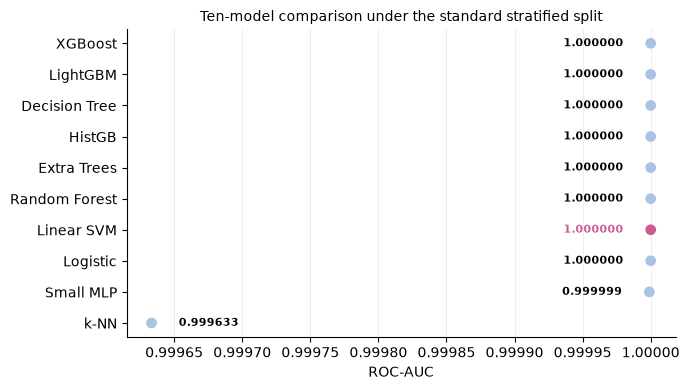

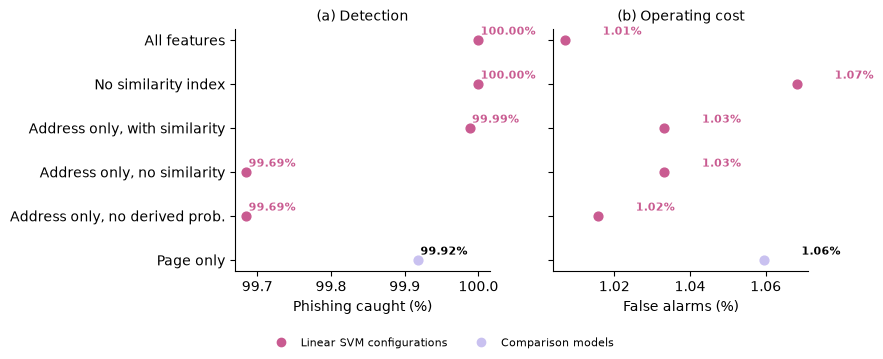

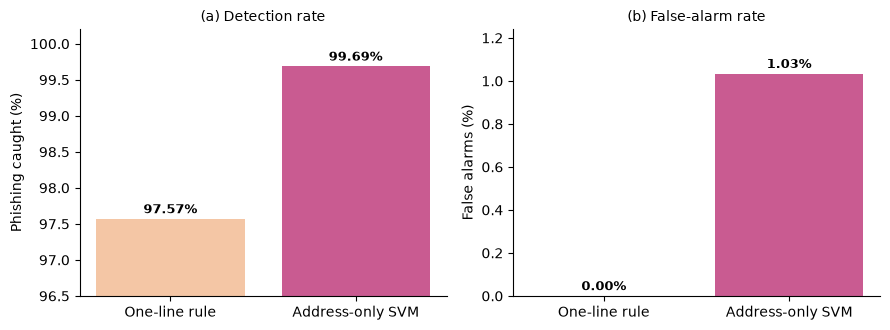

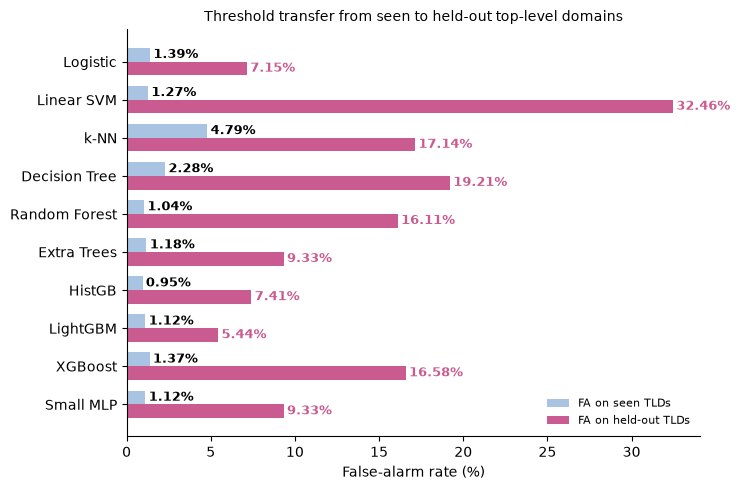

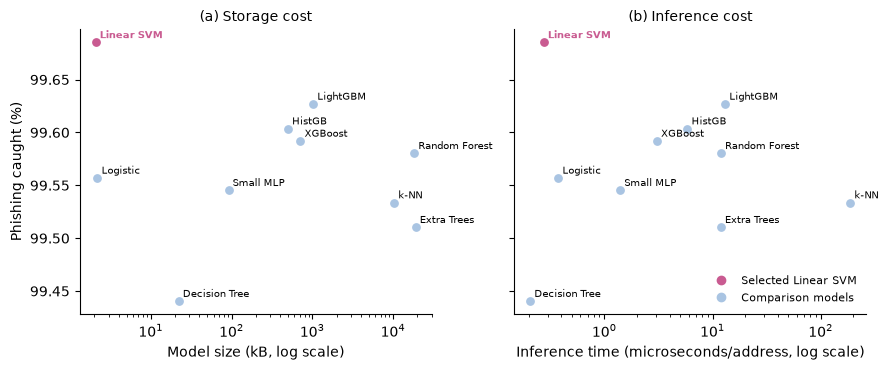

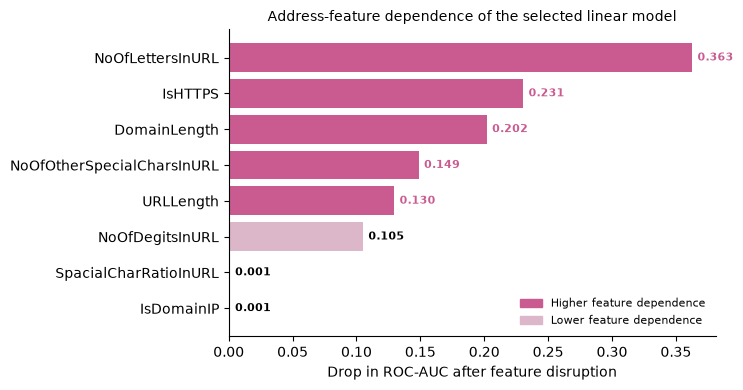

In [1]:
import matplotlib.pyplot as plt, numpy as np, pandas as pd
PINK, LPINK, BLUE, LAV = '#C95B91', '#F0C6D8', '#A9C4E2', '#C9C1F0'
def clean(ax): ax.spines[['top', 'right']].set_visible(False)
rq2, cost = pd.read_csv('report/table_rq2.csv'), pd.read_csv('report/table_rq3_cost.csv')
lad, rule = pd.read_csv('report/table_rq3_feature_ladder.csv'), pd.read_csv('report/table_rq3_one_line_rule.csv', index_col=0).iloc[:, 0]
unseen, drop = pd.read_csv('report/table_rq3_unseen_tld.csv'), pd.read_csv('report/table_rq3_address_features.csv')

# Figure 5: ten-model ROC-AUC under the standard split (dot plot)
d = rq2.sort_values('ROC_AUC').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 4)); ax.set_axisbelow(True); ax.grid(axis='x', color='#EEEEEE')
ax.scatter(d.ROC_AUC, d.index, s=45, color=[PINK if m == 'Linear SVM' else BLUE for m in d.model], zorder=3)
for i, (m, v) in enumerate(zip(d.model, d.ROC_AUC)): ax.text(v - 2e-5 if v > 0.9999 else v + 2e-5, i, '%.6f' % v, va='center', ha='right' if v > 0.9999 else 'left', fontsize=8, fontweight='bold', color=PINK if m == 'Linear SVM' else 'black')
ax.set_yticks(d.index); ax.set_yticklabels(d.model); ax.set_xlabel('ROC-AUC'); ax.set_title('Ten-model comparison under the standard stratified split', fontsize=10); clean(ax)
fig.tight_layout(); fig.savefig('report/paper_fig5_ten_models.png', dpi=300); plt.show()

# Figure 6: best operating point within each feature setting (paper Table 6 picks one model per setting)
SHOW = {'1': 'Linear SVM', '2': 'Linear SVM', '3': 'Linear SVM', '4': 'Linear SVM', '5': 'Linear SVM', '6': 'LightGBM'}
NAMES = {'1': 'All features', '2': 'No similarity index', '3': 'Address only, with similarity', '4': 'Address only, no similarity', '5': 'Address only, no derived prob.', '6': 'Page only'}
rows = [lad[(lad.feature_set.str[0] == k) & (lad.model == m)].iloc[0] for k, m in SHOW.items()]
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True); yy = np.arange(len(rows))[::-1]
for a, col, xl in [(ax[0], 'caught_at_1pct_false_alarms', 'Phishing caught (%)'), (ax[1], 'false_alarm_rate', 'False alarms (%)')]:
    for y_, r in zip(yy, rows):
        v = 100 * r[col]; c = PINK if r.model == 'Linear SVM' else LAV
        a.scatter(v, y_, s=40, color=c, zorder=3); a.text(v + .01 * (1 if col == 'false_alarm_rate' else 0.3), y_ + .12, '%.2f%%' % v, fontsize=8, fontweight='bold', color=c if c == PINK else 'black')
    a.set_xlabel(xl); a.set_yticks(yy); a.set_yticklabels(NAMES.values()); clean(a)
ax[0].set_title('(a) Detection', fontsize=10); ax[1].set_title('(b) Operating cost', fontsize=10)
fig.legend(handles=[plt.Line2D([], [], marker='o', ls='', color=PINK), plt.Line2D([], [], marker='o', ls='', color=LAV)], labels=['Linear SVM configurations', 'Comparison models'], loc='lower center', ncol=2, frameon=False, fontsize=8)
fig.tight_layout(rect=(0, .07, 1, 1)); fig.savefig('report/paper_fig6_feature_settings.png', dpi=300); plt.show()

# Figure 7: one-line rule against the address-only Linear SVM
svm = lad[(lad.feature_set.str[0] == '4') & (lad.model == 'Linear SVM')].iloc[0]
cau, fa = [100 * rule['rule_caught'], 100 * svm.caught_at_1pct_false_alarms], [100 * rule['rule_false_alarm_rate'], 100 * svm.false_alarm_rate]
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4)); lab = ['One-line rule', 'Address-only SVM']
for a, v, yl, t, f in [(ax[0], cau, 'Phishing caught (%)', '(a) Detection rate', '%.2f%%'), (ax[1], fa, 'False alarms (%)', '(b) False-alarm rate', '%.2f%%')]:
    b = a.bar(lab, v, color=['#F4C6A5', PINK]); a.bar_label(b, labels=[f % x for x in v], fontweight='bold', fontsize=9, padding=2); a.set_ylabel(yl); a.set_title(t, fontsize=10); clean(a)
ax[0].set_ylim(96.5, 100.2); ax[1].set_ylim(0, max(fa) * 1.2)
fig.tight_layout(); fig.savefig('report/paper_fig7_rule_vs_svm.png', dpi=300); plt.show()

# Figure 8: threshold transfer from seen to held-out top-level domains
u = unseen[unseen.features.str.startswith('address only')].reset_index(drop=True); y = np.arange(len(u))[::-1]; h = .36
fig, ax = plt.subplots(figsize=(7.5, 5.0))
b1 = ax.barh(y + h/2, 100 * u.false_alarms_seen_tld, h, color=BLUE, label='FA on seen TLDs'); b2 = ax.barh(y - h/2, 100 * u.false_alarms_unseen_tld, h, color=PINK, label='FA on held-out TLDs')
for yy, s_, o in zip(y, 100 * u.false_alarms_seen_tld, 100 * u.false_alarms_unseen_tld): ax.text(s_ + .2, yy + h/2, '%.2f%%' % s_, va='center', fontsize=9, fontweight='bold'); ax.text(o + .2, yy - h/2, '%.2f%%' % o, va='center', fontsize=9, fontweight='bold', color=PINK)
ax.set_yticks(y); ax.set_yticklabels(u.model); ax.set_xlabel('False-alarm rate (%)'); ax.set_title('Threshold transfer from seen to held-out top-level domains', fontsize=10); ax.legend(frameon=False, fontsize=8, loc='lower right'); clean(ax)
fig.tight_layout(); fig.savefig('report/paper_fig8_unseen_tld.png', dpi=300); plt.show()

# Figure 9: cost against detection (storage and inference time, log scales)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for a, col, xl, t in [(ax[0], 'size_kB', 'Model size (kB, log scale)', '(a) Storage cost'), (ax[1], 'microseconds_per_address', 'Inference time (microseconds/address, log scale)', '(b) Inference cost')]:
    for _, r in cost.iterrows():
        s_ = r.model == 'Linear SVM'; v = 100 * r.caught_at_1pct_false_alarms
        a.scatter(r[col], v, s=28, color=PINK if s_ else BLUE, zorder=3); a.annotate(r.model, (r[col], v), xytext=(3, 3), textcoords='offset points', fontsize=7, color=PINK if s_ else 'black', fontweight='bold' if s_ else 'normal')
    a.set_xscale('log'); a.set_xlabel(xl); a.set_title(t, fontsize=10); clean(a)
ax[0].set_ylabel('Phishing caught (%)')
ax[1].legend(handles=[plt.Line2D([], [], marker='o', ls='', color=PINK), plt.Line2D([], [], marker='o', ls='', color=BLUE)], labels=['Selected Linear SVM', 'Comparison models'], frameon=False, fontsize=8, loc='lower right')
fig.tight_layout(); fig.savefig('report/paper_fig9_cost.png', dpi=300); plt.show()

# Figure 10: address-feature dependence of the selected linear model
dd = drop.sort_values('drop_in_ROC_AUC').tail(8); strong = dd.drop_in_ROC_AUC.values >= dd.drop_in_ROC_AUC.max() / 3      # about one third of the largest drop
fig, ax = plt.subplots(figsize=(7.5, 4)); ax.barh(dd.feature, dd.drop_in_ROC_AUC, color=np.where(strong, PINK, '#DCB6C9'))
for yy, v in enumerate(dd.drop_in_ROC_AUC): ax.text(v + .004, yy, '%.3f' % v, va='center', fontsize=8, fontweight='bold', color=PINK if strong[yy] else 'black')
ax.set_xlabel('Drop in ROC-AUC after feature disruption'); ax.set_title('Address-feature dependence of the selected linear model', fontsize=10); clean(ax)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PINK), plt.Rectangle((0, 0), 1, 1, color='#DCB6C9')], labels=['Higher feature dependence', 'Lower feature dependence'], frameon=False, fontsize=8, loc='lower right')
fig.tight_layout(); fig.savefig('report/paper_fig10_address_features.png', dpi=300); plt.show()